In [1]:
import pytesseract
from pytesseract import Output
import cv2
import numpy as np
import PIL
import random
from igraph import *
from queue import Queue

In [80]:
pytesseract.pytesseract.tesseract_cmd = "C:\\Program Files\\Tesseract-OCR\\tesseract.exe" #Set path to Tesseract-OCR

In [128]:
test = cv2.imread('test2.png')

In [115]:
data = pytesseract.image_to_data(test, output_type = Output.DICT)
boxes = []
num_boxes = len(data['level'])
for i in range(num_boxes):
    (x, y, w, h) = (data['left'][i], data['top'][i], data['width'][i], data['height'][i])
    boxes.append((x, y, x + w, y + h))
    cv2.rectangle(test, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(test, str(i + 1), (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255,160,122), 2)
cv2.imshow('img', test)
cv2.waitKey(0)

-1

In [117]:
print(boxes)

[(0, 0, 1219, 811), (93, 84, 594, 747), (94, 84, 594, 367), (94, 84, 568, 103), (94, 84, 176, 103), (183, 84, 269, 103), (275, 88, 317, 99), (323, 84, 381, 99), (389, 84, 452, 103), (459, 84, 472, 99), (480, 84, 568, 103), (95, 108, 566, 127), (95, 108, 152, 126), (160, 108, 222, 127), (230, 108, 303, 123), (310, 108, 416, 123), (424, 112, 474, 127), (480, 108, 511, 123), (519, 108, 566, 123), (95, 132, 576, 151), (95, 132, 163, 147), (170, 132, 221, 147), (228, 132, 286, 147), (293, 132, 353, 151), (359, 132, 393, 147), (401, 136, 411, 147), (418, 136, 454, 151), (462, 132, 510, 147), (516, 132, 576, 147), (94, 156, 568, 175), (94, 156, 110, 171), (116, 157, 149, 171), (157, 156, 187, 171), (195, 156, 263, 171), (269, 156, 300, 171), (308, 156, 355, 171), (362, 156, 426, 175), (432, 156, 486, 171), (494, 156, 503, 171), (510, 156, 523, 171), (529, 156, 568, 171), (94, 180, 544, 199), (94, 180, 142, 195), (148, 180, 181, 195), (187, 180, 214, 195), (220, 180, 252, 195), (259, 180, 347,

In [118]:
random.shuffle(boxes)
print(boxes)

[(700, 112, 743, 123), (94, 636, 156, 655), (716, 636, 792, 655), (148, 688, 191, 699), (95, 108, 152, 126), (721, 708, 785, 723), (433, 468, 449, 483), (356, 304, 414, 315), (519, 108, 566, 123), (394, 396, 436, 411), (661, 444, 770, 463), (216, 372, 268, 391), (1009, 708, 1041, 723), (704, 396, 748, 415), (994, 88, 1024, 99), (162, 640, 198, 651), (228, 132, 286, 147), (244, 396, 337, 415), (734, 588, 815, 607), (195, 252, 298, 267), (931, 736, 970, 751), (359, 132, 393, 147), (629, 276, 1124, 295), (832, 252, 920, 267), (885, 468, 969, 487), (94, 636, 581, 655), (510, 156, 523, 171), (247, 564, 335, 583), (641, 252, 920, 270), (95, 612, 577, 631), (943, 372, 979, 387), (437, 492, 532, 507), (389, 324, 477, 343), (94, 732, 124, 747), (623, 564, 1096, 583), (629, 137, 634, 142), (239, 636, 314, 655), (861, 636, 920, 655), (220, 180, 252, 195), (623, 468, 708, 487), (95, 348, 336, 367), (822, 588, 859, 607), (308, 156, 355, 171), (95, 420, 137, 435), (458, 277, 501, 291), (915, 396, 97

In [119]:
n = len(boxes) // 8  #Decreasing the number of bounding boxes otherwise it will be very computationally expensive
print(n)

64


In [120]:
graph = Graph(directed = True)
graph.add_vertices(n)
for i in range(len(graph.vs)):
    graph.vs[i]["id"]= i
    graph.vs[i]["label"]= str(i)
counter = 0

#Randomizing Edges so that graph remains connected and we can apply Topological Sort

for i in range(n):
    for j in range(i + 1, n):
        if random.random() < 0.5 and counter < 5: 
            graph.add_edge(i, j)
            counter += 1
        elif counter >= 5:
            break
    counter = 0

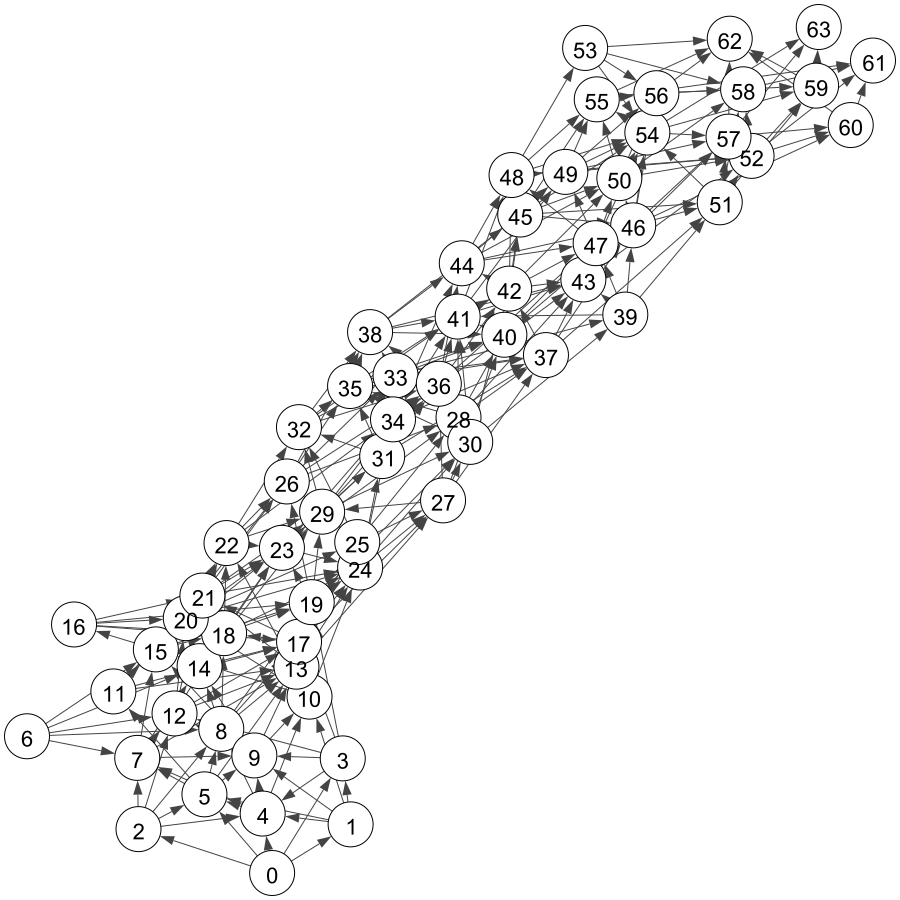

In [121]:
visual_style = {}
visual_style["bbox"] = (900,900)
visual_style["margin"] = 27
visual_style["vertex_color"] = 'white'
visual_style["vertex_size"] = 45
visual_style["vertex_label_size"] = 22
visual_style["edge_curved"] = False
my_layout = graph.layout('auto')
visual_style["layout"] = my_layout
plot(graph, **visual_style)

In [122]:
print(graph.neighbors(0, mode = IN))

[]


In [123]:
#TOPOLOGICAL SORT

In [124]:
def topologicalHelper(g, visited, queue, inDegrees):
    topoSorted = []
    while not queue.empty():
        v = queue.get()
        topoSorted.append(v)
        visited += 1
        adjOutNodes = g.neighbors(v, mode = OUT)
        for vertex in adjOutNodes:
            inDegrees[vertex] -= 1
            if inDegrees[vertex] == 0:
                queue.put(vertex)
    return topoSorted, visited

In [125]:
def TopologicalSort(g, num_vertices, boxes):
    visited = 0
    inDegrees = []
    for i in range(num_vertices):
        inDegree = len(g.neighbors(i, mode = IN))
        inDegrees.append(inDegree)
    queue = Queue(maxsize = num_vertices)
    for i in range(len(inDegrees)):
        if inDegrees[i] == 0:
            queue.put(i)
    topoSorted, visited = topologicalHelper(g, visited, queue, inDegrees)
    if visited != num_vertices:
        print("Topological Sort is not Possible")
        return
    print("Bounding Box ID : Coordinates")
    print("   (StartX, StartY, EndX, EndY)")
    for i in topoSorted:
        print(i, " : ", boxes[i])

In [126]:
TopologicalSort(graph, n, boxes)

Bounding Box ID : Coordinates
   (StartX, StartY, EndX, EndY)
0  :  (700, 112, 743, 123)
6  :  (433, 468, 449, 483)
1  :  (94, 636, 156, 655)
2  :  (716, 636, 792, 655)
3  :  (148, 688, 191, 699)
4  :  (95, 108, 152, 126)
5  :  (721, 708, 785, 723)
7  :  (356, 304, 414, 315)
8  :  (519, 108, 566, 123)
11  :  (216, 372, 268, 391)
9  :  (394, 396, 436, 411)
10  :  (661, 444, 770, 463)
12  :  (1009, 708, 1041, 723)
14  :  (994, 88, 1024, 99)
15  :  (162, 640, 198, 651)
13  :  (704, 396, 748, 415)
16  :  (228, 132, 286, 147)
17  :  (244, 396, 337, 415)
20  :  (931, 736, 970, 751)
18  :  (734, 588, 815, 607)
19  :  (195, 252, 298, 267)
21  :  (359, 132, 393, 147)
22  :  (629, 276, 1124, 295)
23  :  (832, 252, 920, 267)
24  :  (885, 468, 969, 487)
25  :  (94, 636, 581, 655)
26  :  (510, 156, 523, 171)
27  :  (247, 564, 335, 583)
28  :  (641, 252, 920, 270)
29  :  (95, 612, 577, 631)
30  :  (943, 372, 979, 387)
31  :  (437, 492, 532, 507)
32  :  (389, 324, 477, 343)
33  :  (94, 732, 124, 747)

In [129]:
for i in range(n):
    (x1, y1, x2, y2) = (boxes[i][0], boxes[i][1], boxes[i][2], boxes[i][3])
    cv2.rectangle(test, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(test, str(i + 1), (x1, y1), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255,160,122), 2)
cv2.imshow('img', test)
cv2.waitKey(0)

-1